In [2]:
import pandas as pd 

inventory=pd.read_csv("items_and_stock.csv")

inventory.head()

,Item code,Description,Category,Supplier,Warehouse,Period,Unit cost,Landed cost (with freight),Average cost (stock value / qty),Selling price,...,Qty on hand,Stock value,Qty allocated to orders,Qty available,Weeks of cover,Days since last sale (month end),Units sold,Revenue,Lost sales units (stockout),Stocked out (Y/N)
0,IT-10001,Ball bearing 20-1,Bearings,Clearwater Supply,Main warehouse,2024-09,1.10,1.10,1.084438,1.45,...,489,530.29,13,476,14.09,2,204,295.80,0,N
1,IT-10001,Ball bearing 20-1,Bearings,Clearwater Supply,Main warehouse,2024-10,1.07,1.07,1.082943,1.45,...,384,415.85,57,327,9.72,1,161,233.45,0,N
2,IT-10001,Ball bearing 20-1,Bearings,Clearwater Supply,Main warehouse,2024-11,1.07,1.07,1.076872,1.45,...,438,471.67,51,387,8.75,1,286,414.70,0,N
3,IT-10001,Ball bearing 20-1,Bearings,Clearwater Supply,Main warehouse,2024-12,1.09,1.09,1.082397,1.45,...,655,708.97,57,598,15.71,0,101,146.45,0,N
4,IT-10001,Ball bearing 20-1,Bearings,Clearwater Supply,Main warehouse,2025-01,1.07,1.07,1.081253,1.45,...,471,509.27,13,458,9.70,0,251,363.95,0,N


In [3]:
inventory.shape

(3600, 23)

In [4]:
inventory.columns

Index(['Item code', 'Description', 'Category', 'Supplier', 'Warehouse',
       'Period', 'Unit cost', 'Landed cost (with freight)',
       'Average cost (stock value / qty)', 'Selling price',
       'Lead time planned days', 'Lead time actual days', 'Qty received',
       'Qty on hand', 'Stock value', 'Qty allocated to orders',
       'Qty available', 'Weeks of cover', 'Days since last sale (month end)',
       'Units sold', 'Revenue', 'Lost sales units (stockout)',
       'Stocked out (Y/N)'],
      dtype='str')

In [5]:
inventory.info()

<class 'pandas.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 23 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Item code                         3600 non-null   str    
 1   Description                       3600 non-null   str    
 2   Category                          3600 non-null   str    
 3   Supplier                          3600 non-null   str    
 4   Warehouse                         3600 non-null   str    
 5   Period                            3600 non-null   str    
 6   Unit cost                         3600 non-null   float64
 7   Landed cost (with freight)        3600 non-null   float64
 8   Average cost (stock value / qty)  3600 non-null   float64
 9   Selling price                     3600 non-null   float64
 10  Lead time planned days            3600 non-null   int64  
 11  Lead time actual days             2461 non-null   float64
 12  Qty received     

In [6]:
inventory.isnull().sum()

Item code                              0
Description                            0
Category                               0
Supplier                               0
Warehouse                              0
Period                                 0
Unit cost                              0
Landed cost (with freight)             0
Average cost (stock value / qty)       0
Selling price                          0
Lead time planned days                 0
Lead time actual days               1139
Qty received                           0
Qty on hand                            0
Stock value                            0
Qty allocated to orders                0
Qty available                          0
Weeks of cover                       116
Days since last sale (month end)       0
Units sold                             0
Revenue                                0
Lost sales units (stockout)            0
Stocked out (Y/N)                      0
dtype: int64

In [7]:
inventory.duplicated().sum()

np.int64(0)

In [8]:
inventory["Item code"].nunique()

150

In [9]:
inventory["Period"].nunique()

24

In [10]:
inventory.duplicated(subset=["Item code","Period"]).sum()

np.int64(0)

In [11]:
inventory.groupby("Item code")["Period"].nunique()

Item code
IT-10001    24
IT-10002    24
IT-10003    24
IT-10004    24
IT-10005    24
            ..
IT-10146    24
IT-10147    24
IT-10148    24
IT-10149    24
IT-10150    24
Name: Period, Length: 150, dtype: int64

In [45]:
inventory.groupby("Item code")["Period"].nunique().eq(24).all()

np.True_

In [13]:
months_per_product=inventory.groupby("Item code")["Period"].nunique()
months_per_product[months_per_product !=24]

Series([], Name: Period, dtype: int64)

In [14]:


print("Number of products:", months_per_product.size)
print("Number of product:", months_per_product.min())
print("Number of product:", months_per_product.max())
print("Number of product:", months_per_product.eq(24).all()) 

Number of products: 150
Number of product: 24
Number of product: 24
Number of product: True


In [15]:
inventory["Category"].value_counts()

Category
Electrical            840
Fluid power           792
Bearings              744
Fasteners             648
Power transmission    576
Name: count, dtype: int64

In [16]:
inventory.groupby("Category")["Item code"].nunique()

Category
Bearings              31
Electrical            35
Fasteners             27
Fluid power           33
Power transmission    24
Name: Item code, dtype: int64

In [17]:
inventory.groupby("Category")["Stock value"].sum().sort_values(ascending=False)

Category
Fluid power           9829394.98
Bearings              8683301.47
Fasteners             7519372.92
Electrical            7094160.56
Power transmission    4984093.53
Name: Stock value, dtype: float64

In [18]:
inventory.groupby("Category")["Revenue"].sum().sort_values(ascending=False)

Category
Fluid power           6138005.56
Bearings              5253716.72
Electrical            4601753.60
Fasteners             4548349.09
Power transmission    3224943.44
Name: Revenue, dtype: float64

In [19]:
inventory.groupby("Period")["Revenue"].sum().sort_values(ascending=False)

Period
2025-05    1122824.02
2026-07    1090556.27
2025-11    1049985.89
2026-05    1046029.27
2025-10    1045390.73
2025-07    1043578.84
2026-06    1020157.71
2026-08    1011462.64
2025-12    1011206.74
2026-03     998348.52
2025-08     992581.05
2025-03     990927.12
2026-01     989339.92
2024-09     987503.60
2025-01     976995.45
2025-09     959512.91
2025-04     950527.00
2025-02     938881.76
2026-04     935183.23
2026-02     933642.93
2024-10     930407.33
2024-12     925045.57
2024-11     919510.90
2025-06     897169.01
Name: Revenue, dtype: float64

In [20]:
monthly_revenue=inventory.groupby("Period")["Revenue"].sum().sort_index()
monthly_revenue

Period
2024-09     987503.60
2024-10     930407.33
2024-11     919510.90
2024-12     925045.57
2025-01     976995.45
2025-02     938881.76
2025-03     990927.12
2025-04     950527.00
2025-05    1122824.02
2025-06     897169.01
2025-07    1043578.84
2025-08     992581.05
2025-09     959512.91
2025-10    1045390.73
2025-11    1049985.89
2025-12    1011206.74
2026-01     989339.92
2026-02     933642.93
2026-03     998348.52
2026-04     935183.23
2026-05    1046029.27
2026-06    1020157.71
2026-07    1090556.27
2026-08    1011462.64
Name: Revenue, dtype: float64

In [21]:
print("Starting revenue:", monthly_revenue.iloc[0])
print("Latest revenue:", monthly_revenue.iloc[-1])
print("Highest revenue:", monthly_revenue.max())
print("Lowest revenue:", monthly_revenue.min())

Starting revenue: 987503.6
Latest revenue: 1011462.64
Highest revenue: 1122824.02
Lowest revenue: 897169.01


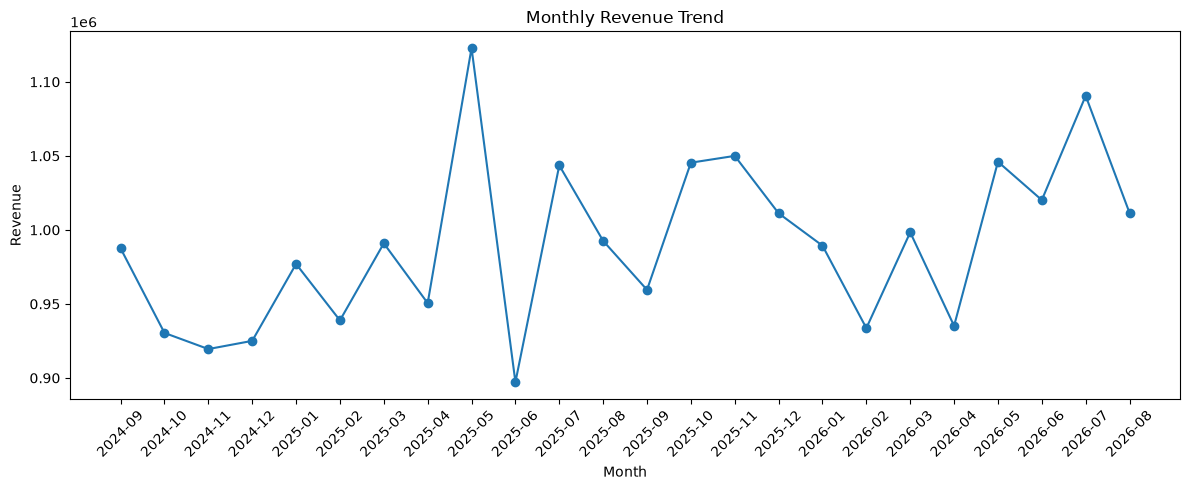

In [22]:
import matplotlib.pyplot as plt 

plt.figure(figsize=(12,5))
plt.plot(monthly_revenue.index,monthly_revenue.values,marker='o')

plt.xlabel("Month")
plt.ylabel("Revenue")
plt.title("Monthly Revenue Trend")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [23]:
product_revenue=(inventory.groupby(["Item code","Description"])["Revenue"].sum().sort_values(ascending=False))
product_revenue.head(10)

Item code  Description            
IT-10128   Filter cartridge 10-128    822281.60
IT-10056   Sensor unit 10-56          626898.35
IT-10064   Pillow block S-64          623138.61
IT-10103   Anchor bolt S-103          613516.66
IT-10083   Bolt assortment 10-83      593083.60
IT-10007   Bolt assortment A-7        565772.88
IT-10115   Pillow block A-115         549248.46
IT-10013   Control switch L-13        536323.83
IT-10086   Roller bearing 20-86       505370.00
IT-10133   Filter cartridge M-133     500710.72
Name: Revenue, dtype: float64

In [24]:
product_revenue.sort_values(ascending=True).head(10)

Item code  Description          
IT-10001   Ball bearing 20-1         6878.22
IT-10005   Hydraulic hose L-5        8136.82
IT-10131   Relay 20-131              8162.55
IT-10134   Bolt assortment M-134    10593.74
IT-10129   Hydraulic hose S-129     11697.24
IT-10150   Drive belt 20-150        12539.79
IT-10031   Anchor bolt M-31         13230.65
IT-10088   Relay 20-88              14469.91
IT-10069   Roller bearing M-69      14897.88
IT-10107   Pressure valve L-107     15196.88
Name: Revenue, dtype: float64

In [46]:
average_stock_value = (
    inventory.groupby(["Item code", "Description"])["Stock value"]
    .mean()
    .sort_values(ascending=False)
)

average_stock_value.head(10)

Item code  Description            
IT-10092   Hydraulic hose B-92        69480.984167
IT-10007   Bolt assortment A-7        67630.484583
IT-10055   Control switch L-55        48486.988333
IT-10086   Roller bearing 20-86       42889.975833
IT-10083   Bolt assortment 10-83      41632.263750
IT-10122   Roller bearing L-122       40374.138750
IT-10113   Ball bearing 20-113        38712.615000
IT-10112   Gear set B-112             38320.370833
IT-10128   Filter cartridge 10-128    34885.254583
IT-10064   Pillow block S-64          34313.193750
Name: Stock value, dtype: float64

In [26]:
print(average_stock_value.name)
print(inventory["Stock value"].dtype)

Revenue
float64


In [27]:
print("Average stock value variable:")
print(average_stock_value.head(3))

print("\nStock value column:")
print(inventory["Stock value"].head(3))

print("\nRevenue column:")
print(inventory["Revenue"].head(3))

Average stock value variable:
Item code  Description            
IT-10128   Filter cartridge 10-128    34261.733333
IT-10056   Sensor unit 10-56          26120.764583
IT-10064   Pillow block S-64          25964.108750
Name: Revenue, dtype: float64

Stock value column:
0    530.29
1    415.85
2    471.67
Name: Stock value, dtype: float64

Revenue column:
0    295.80
1    233.45
2    414.70
Name: Revenue, dtype: float64


In [28]:
average_stock_value=(inventory.groupby(["Item code","Description"])["Stock value"].mean().sort_values(ascending=False))
average_stock_value.head(10)

Item code  Description            
IT-10092   Hydraulic hose B-92        69480.984167
IT-10007   Bolt assortment A-7        67630.484583
IT-10055   Control switch L-55        48486.988333
IT-10086   Roller bearing 20-86       42889.975833
IT-10083   Bolt assortment 10-83      41632.263750
IT-10122   Roller bearing L-122       40374.138750
IT-10113   Ball bearing 20-113        38712.615000
IT-10112   Gear set B-112             38320.370833
IT-10128   Filter cartridge 10-128    34885.254583
IT-10064   Pillow block S-64          34313.193750
Name: Stock value, dtype: float64

In [29]:
print(average_stock_value.name)

Stock value


In [30]:
product_units_sold=(inventory.groupby(["Item code","Description"])["Units sold"].sum().sort_values(ascending=False))
product_units_sold.head(10)

Item code  Description           
IT-10046   Pillow block A-46         30009
IT-10039   Pillow block 20-39        27337
IT-10044   Gear set L-44             26868
IT-10043   Control switch S-43       26717
IT-10079   Filter cartridge 10-79    24796
IT-10061   Pressure valve 20-61      23403
IT-10118   Sensor unit M-118         22466
IT-10143   Gear set A-143            20283
IT-10101   Drive belt L-101          20187
IT-10053   Relay B-53                20084
Name: Units sold, dtype: int64

In [31]:
product_lost_sales=(inventory.groupby(["Item code","Description"])["Lost sales units (stockout)"].sum().sort_values(ascending=False))
product_lost_sales.head(10)

Item code  Description           
IT-10063   Anchor bolt B-63          2436
IT-10130   Pillow block S-130        1948
IT-10066   Filter cartridge A-66     1602
IT-10135   Bolt assortment M-135     1155
IT-10043   Control switch S-43       1048
IT-10010   Relay L-10                 695
IT-10023   Sensor unit L-23           676
IT-10079   Filter cartridge 10-79     675
IT-10148   Pillow block A-148         607
IT-10080   Anchor bolt A-80           598
Name: Lost sales units (stockout), dtype: int64

In [32]:
q1=inventory["Revenue"].quantile(0.25)
q2=inventory["Revenue"].quantile(0.50)
q3=inventory["Revenue"].quantile(0.75)

print("Q1:",q1)
print("Q2(Median):",q2)
print("Q3:",q3)

Q1: 1555.31
Q2(Median): 3812.39
Q3: 8188.485


In [33]:
IQR=q3-q1
print(IQR)

6633.174999999999


In [34]:
print(round(IQR,2))

6633.17


In [35]:
lower_bound=q1-(1.5*IQR)
upper_bound=q3+(1.5*IQR)

print("Lower bound:",lower_bound)
print("Upper bound:",upper_bound)

Lower bound: -8394.4525
Upper bound: 18138.247499999998


In [36]:
inventory.groupby("Category")["Lost sales units (stockout)"].sum().sort_values(ascending=False)

Category
Fasteners             4939
Bearings              3501
Electrical            3335
Fluid power           2901
Power transmission    1258
Name: Lost sales units (stockout), dtype: int64

In [37]:
stockout_records=inventory[inventory["Stocked out (Y/N)"]=="Y"]
print(stockout_records)

     Item code           Description     Category           Supplier  \
63    IT-10003    Pressure valve A-3  Fluid power     Summit Trading   
70    IT-10003    Pressure valve A-3  Fluid power     Summit Trading   
71    IT-10003    Pressure valve A-3  Fluid power     Summit Trading   
72    IT-10004  Filter cartridge A-4  Fluid power     Summit Trading   
79    IT-10004  Filter cartridge A-4  Fluid power     Summit Trading   
...        ...                   ...          ...                ...   
3532  IT-10148    Pillow block A-148     Bearings  Clearwater Supply   
3534  IT-10148    Pillow block A-148     Bearings  Clearwater Supply   
3536  IT-10148    Pillow block A-148     Bearings  Clearwater Supply   
3544  IT-10148    Pillow block A-148     Bearings  Clearwater Supply   
3547  IT-10148    Pillow block A-148     Bearings  Clearwater Supply   

           Warehouse   Period  Unit cost  Landed cost (with freight)  \
63    Main warehouse  2025-12      74.60                       

In [38]:
stockout_records.groupby("Category")["Item code"].count().sort_values(ascending=False)

Category
Fasteners             27
Bearings              24
Power transmission    22
Electrical            21
Fluid power           20
Name: Item code, dtype: int64

In [39]:
import pandas as pd
import matplotlib.pyplot as plt

# Count total records and stockout records by category
stockout_summary = (
    inventory.assign(
        stockout=inventory["Stocked out (Y/N)"].eq("Y")
    )
    .groupby("Category")
    .agg(
        total_records=("stockout", "size"),
        stockout_records=("stockout", "sum")
    )
)

# Calculate stockout percentage
stockout_summary["stockout_rate_pct"] = (
    stockout_summary["stockout_records"]
    / stockout_summary["total_records"] * 100
)

stockout_summary = stockout_summary.sort_values(
    "stockout_rate_pct", ascending=False
).round(2)

display(stockout_summary)

,total_records,stockout_records,stockout_rate_pct
Category,,,
Fasteners,648,27,4.17
Power transmission,576,22,3.82
Bearings,744,24,3.23
Fluid power,792,20,2.53
Electrical,840,21,2.50


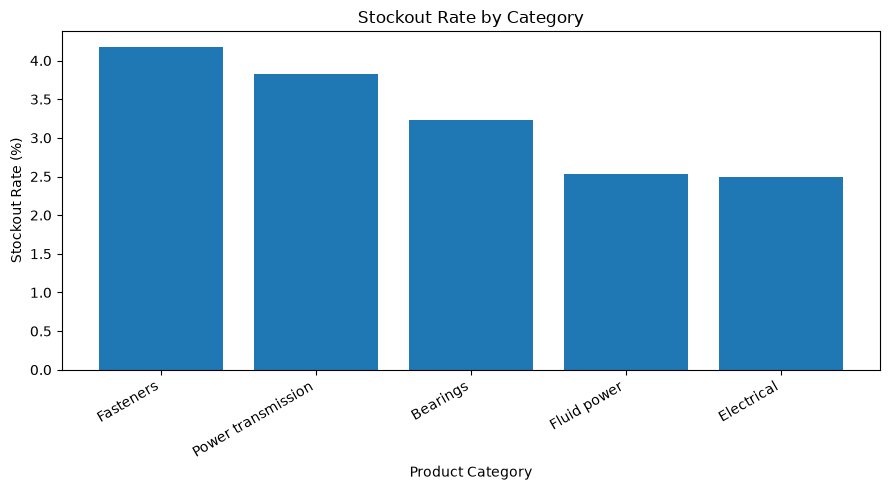

In [40]:
plt.figure(figsize=(9, 5))

plt.bar(
    stockout_summary.index,
    stockout_summary["stockout_rate_pct"]
)

plt.title("Stockout Rate by Category")
plt.xlabel("Product Category")
plt.ylabel("Stockout Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

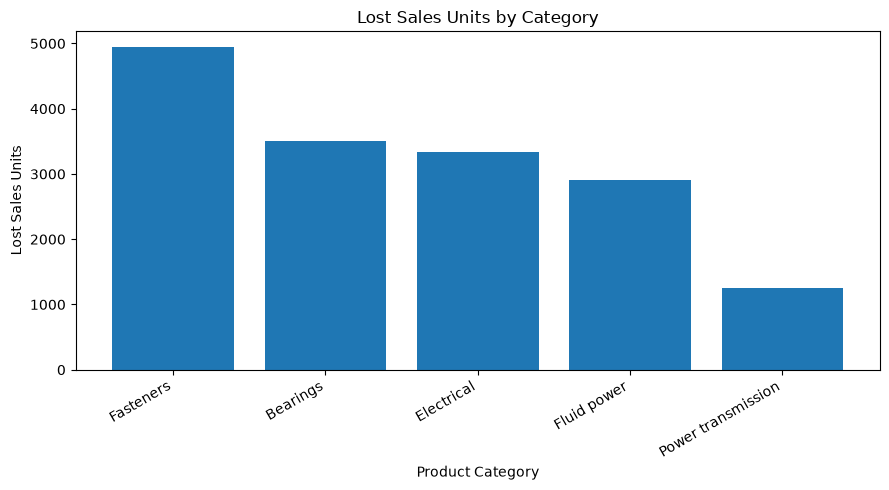

In [41]:
lost_sales_by_category = (
    inventory.groupby("Category")["Lost sales units (stockout)"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(9, 5))
plt.bar(
    lost_sales_by_category.index,
    lost_sales_by_category.values
)

plt.title("Lost Sales Units by Category")
plt.xlabel("Product Category")
plt.ylabel("Lost Sales Units")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

In [42]:
import plotly.express as px
print(px.__version__ if hasattr(px, "__version__") else "Plotly is available")

Plotly is available


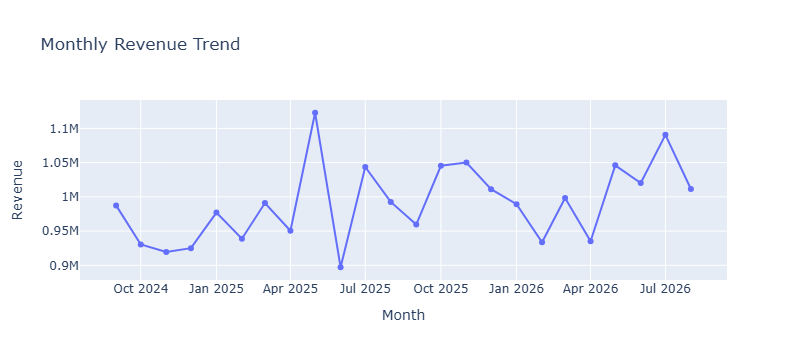

In [43]:
monthly_revenue = inventory.groupby("Period")["Revenue"].sum()

monthly_revenue.index = monthly_revenue.index.astype(str)

fig = px.line(
    x=monthly_revenue.index,
    y=monthly_revenue.values,
    markers=True,
    title="Monthly Revenue Trend",
    labels={"x": "Month", "y": "Revenue"}
)

fig.show()

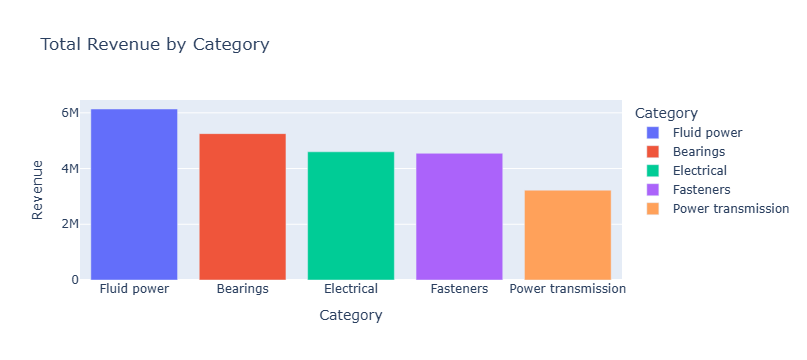

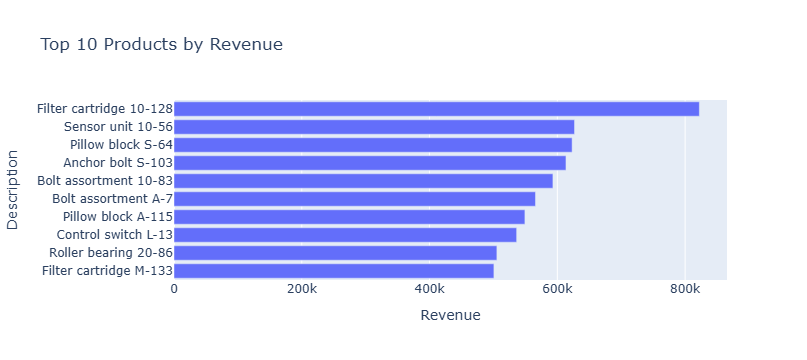

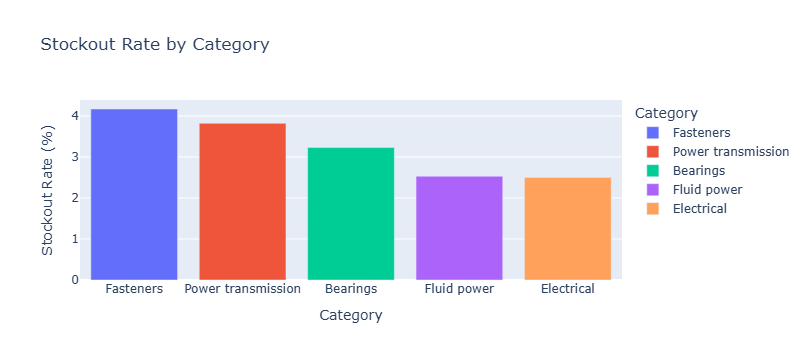

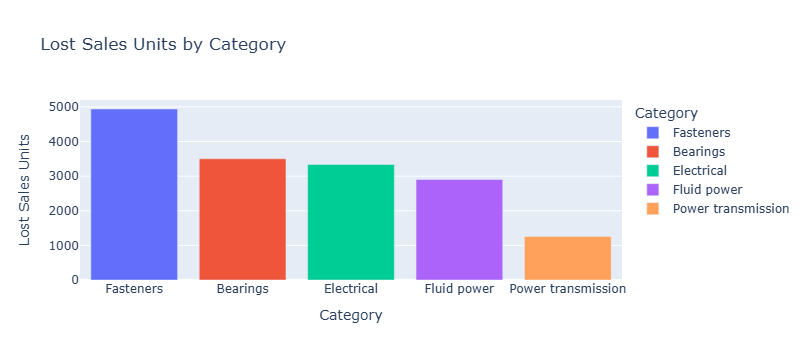

In [44]:
import plotly.express as px

# 1. Revenue by category
category_revenue = (
    inventory.groupby("Category")["Revenue"]
    .sum()
    .reset_index()
    .sort_values("Revenue", ascending=False)
)

fig1 = px.bar(
    category_revenue,
    x="Category",
    y="Revenue",
    title="Total Revenue by Category",
    color="Category"
)
fig1.show()


# 2. Top 10 products by revenue
product_revenue = (
    inventory.groupby(["Item code", "Description"])["Revenue"]
    .sum()
    .reset_index()
    .nlargest(10, "Revenue")
)

fig2 = px.bar(
    product_revenue.sort_values("Revenue"),
    x="Revenue",
    y="Description",
    orientation="h",
    title="Top 10 Products by Revenue"
)
fig2.show()


# 3. Stockout rate by category
fig3 = px.bar(
    stockout_summary.reset_index(),
    x="Category",
    y="stockout_rate_pct",
    title="Stockout Rate by Category",
    color="Category",
    labels={"stockout_rate_pct": "Stockout Rate (%)"}
)
fig3.show()


# 4. Lost sales by category
lost_sales_chart = lost_sales_by_category.rename(
    "Lost Sales Units"
).reset_index()

fig4 = px.bar(
    lost_sales_chart,
    x="Category",
    y="Lost Sales Units",
    title="Lost Sales Units by Category",
    color="Category"
)
fig4.show()